In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [17]:
df = pd.read_csv("personal_expense_dataset.csv")
df.head()

,Date,Category,Amount,Payment_Mode,Month
0,1/1/2024,Transport,3279,Cash,May
1,1/2/2024,Entertainment,2080,Card,December
2,1/2/2024,Transport,3217,Online,December
3,1/2/2024,Utilities,1054,Online,May
4,1/5/2024,Food,13249,Cash,December


In [18]:
df.shape

(1000, 5)

In [19]:
df.columns

Index(['Date', 'Category', 'Amount', 'Payment_Mode', 'Month'], dtype='object')

In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Date          1000 non-null   object
 1   Category      1000 non-null   object
 2   Amount        1000 non-null   int64 
 3   Payment_Mode  1000 non-null   object
 4   Month         1000 non-null   object
dtypes: int64(1), object(4)
memory usage: 39.2+ KB


In [21]:
df.isnull().sum()

Date            0
Category        0
Amount          0
Payment_Mode    0
Month           0
dtype: int64

In [23]:
df.columns.tolist()

['Date', 'Category', 'Amount', 'Payment_Mode', 'Month']

In [24]:
df["Date"] = pd.to_datetime(df["Date"])

In [25]:
df["Amount"].describe()

count     1000.000000
mean      7676.692000
std       4347.352771
min        101.000000
25%       3781.250000
50%       7938.000000
75%      11442.250000
max      14999.000000
Name: Amount, dtype: float64

In [26]:
category_expenses = df.groupby("Category")["Amount"].sum().sort_values(ascending=False)
category_expenses

Category
Food             1225416
Shopping         1163286
Health           1135122
Entertainment    1126859
Transport        1065197
Rent              997894
Utilities         962918
Name: Amount, dtype: int64

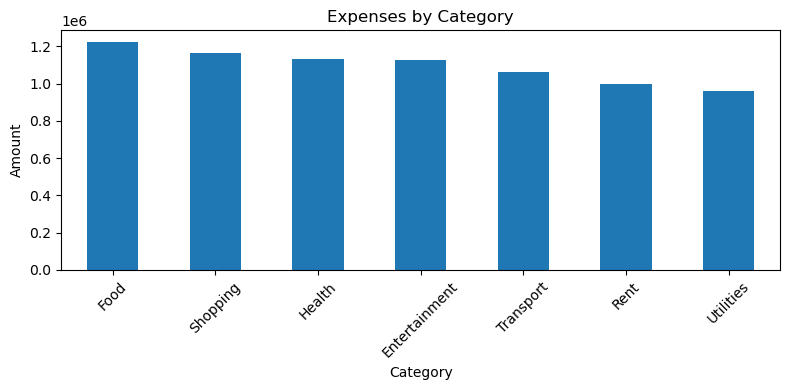

In [27]:
category_expenses.plot(kind="bar", figsize=(8, 4))
plt.title("Expenses by Category")
plt.xlabel("Category")
plt.ylabel("Amount")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [29]:
payment_expenses = df.groupby("Payment_Mode")["Amount"].sum()
payment_expenses

Payment_Mode
Card      2587278
Cash      2661495
Online    2427919
Name: Amount, dtype: int64

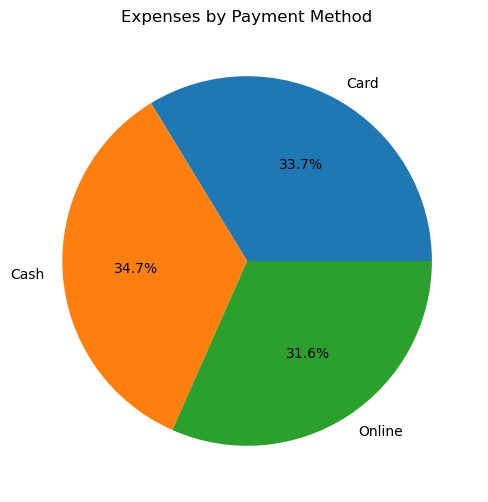

In [30]:
payment_expenses.plot(kind="pie", autopct="%1.1f%%", figsize=(6, 6))
plt.title("Expenses by Payment Method")
plt.ylabel("")
plt.show()

In [31]:
monthly_expenses = df.groupby("Month")["Amount"].sum()
monthly_expenses

Month
April        649464
August       721611
December     608184
February     628661
January      619460
July         563018
June         692346
March        594558
May          682240
November     694766
October      598291
September    624093
Name: Amount, dtype: int64

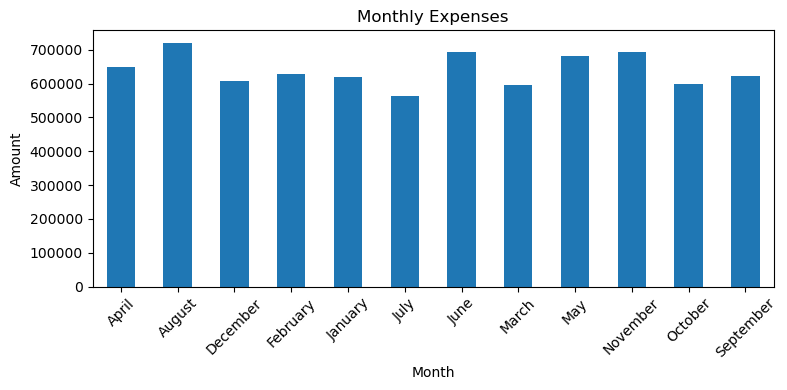

In [32]:
monthly_expenses.plot(kind="bar", figsize=(8, 4))
plt.title("Monthly Expenses")
plt.xlabel("Month")
plt.ylabel("Amount")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [33]:
df["Month"] = df["Date"].dt.month_name()

In [34]:
df["Day"] = df["Date"].dt.day_name()
daily_expenses = df.groupby("Day")["Amount"].sum()
daily_expenses

Day
Friday       1130984
Monday       1215809
Saturday     1052039
Sunday       1130203
Thursday      966819
Tuesday      1094663
Wednesday    1086175
Name: Amount, dtype: int64

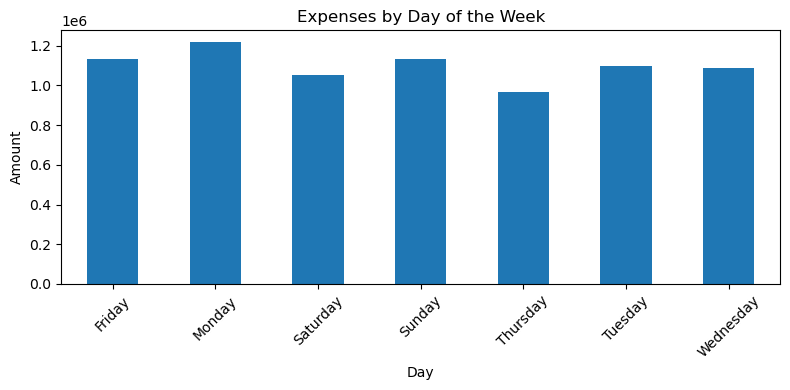

In [35]:
daily_expenses.plot(kind="bar", figsize=(8, 4))
plt.title("Expenses by Day of the Week")
plt.xlabel("Day")
plt.ylabel("Amount")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [36]:
category_expenses.idxmax()

'Food'

In [37]:
monthly_expenses = df.groupby("Month")["Amount"].sum()
monthly_expenses.idxmax()

'August'

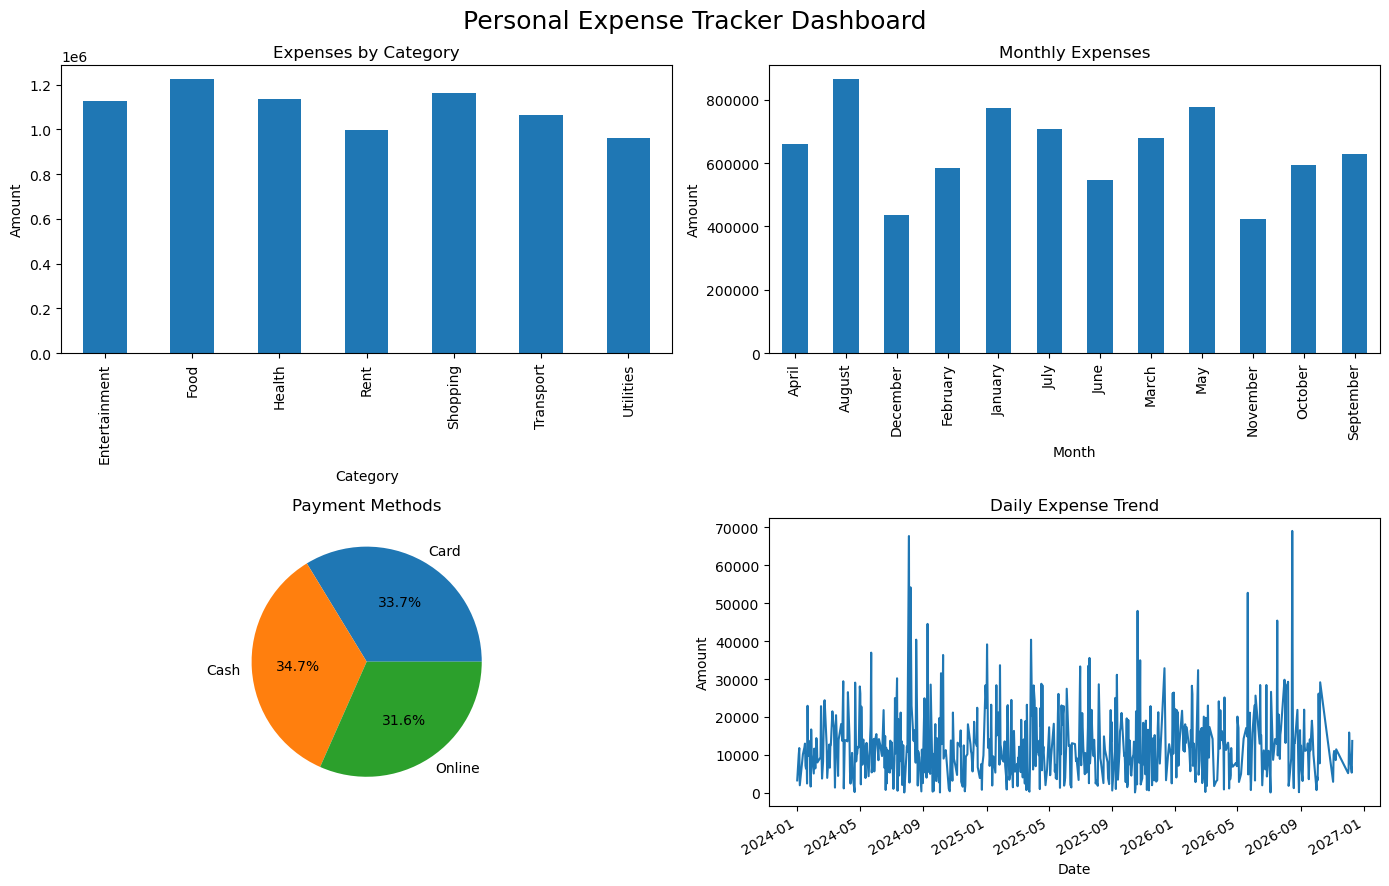

In [39]:
import matplotlib.pyplot as plt

total_expenses = df["Amount"].sum()
average_expense = df["Amount"].mean()
highest_category = df.groupby("Category")["Amount"].sum().idxmax()

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

fig.suptitle("Personal Expense Tracker Dashboard", fontsize=18)

# Category-wise expenses
df.groupby("Category")["Amount"].sum().plot(
    kind="bar", ax=axes[0, 0], title="Expenses by Category"
)
axes[0, 0].set_ylabel("Amount")

# Monthly expenses
df.groupby("Month")["Amount"].sum().plot(
    kind="bar", ax=axes[0, 1], title="Monthly Expenses"
)
axes[0, 1].set_ylabel("Amount")

# Payment method analysis
df.groupby("Payment_Mode")["Amount"].sum().plot(
    kind="pie", autopct="%1.1f%%", ax=axes[1, 0],
    title="Payment Methods"
)
axes[1, 0].set_ylabel("")

# Daily expense trend
df.groupby("Date")["Amount"].sum().plot(
    kind="line", ax=axes[1, 1], title="Daily Expense Trend"
)
axes[1, 1].set_ylabel("Amount")

plt.tight_layout()
plt.show()